In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
data = [
    [2, 40], [3, 45], [4, 50], [2, 42], [3, 48],
    [8, 85], [9, 90], [7, 80], [8, 88], [9, 95],
    [5, 60], [6, 65], [5, 62], [6, 68], [5, 58],
    [2, 35], [3, 42], [4, 47], [8, 92], [7, 87],
    [5, 63], [6, 70], [9, 93], [3, 38], [7, 82]
]

df = pd.DataFrame(data, columns=['Study_Hours', 'Attendance'])

print(df.head())
print("Shape:", df.shape)

   Study_Hours  Attendance
0            2          40
1            3          45
2            4          50
3            2          42
4            3          48
Shape: (25, 2)


In [3]:
X = df[['Study_Hours', 'Attendance']]

print(X.head())

   Study_Hours  Attendance
0            2          40
1            3          45
2            4          50
3            2          42
4            3          48


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [5]:
wcss = []

for k in range(2, 6):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

print("WCSS:", wcss)

WCSS: [11.971394966152209, 3.7371998181034054, 2.5810047605403796, 1.679159274034601]


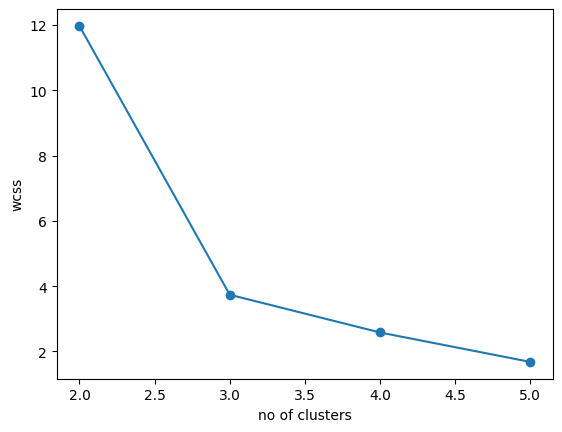

In [6]:
plt.plot(range(2,6),wcss,marker='o')
plt.xlabel("no of clusters")
plt.ylabel("wcss")
plt.show()

In [7]:
final_model = KMeans(
    n_clusters= 3,
    random_state= 42,
    n_init= 10
)

In [8]:
df['cluster'] =  final_model.fit_predict(X_scaled)

In [9]:
df

,Study_Hours,Attendance,cluster
0,2,40,1
1,3,45,1
2,4,50,1
3,2,42,1
4,3,48,1
5,8,85,0
6,9,90,0
7,7,80,0
8,8,88,0
9,9,95,0


In [15]:
centriods =  scaler.inverse_transform(final_model.cluster_centers_)

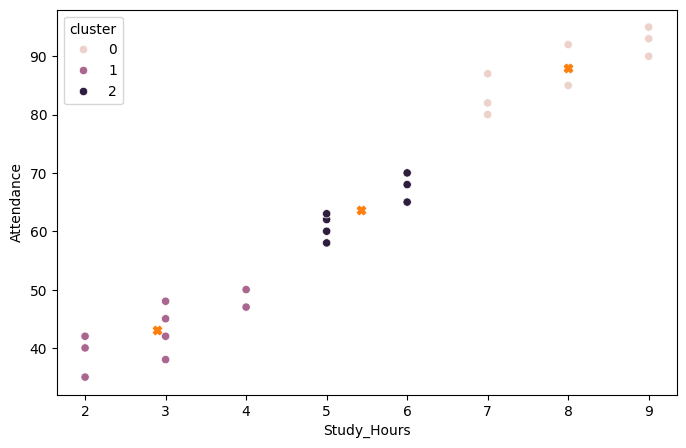

In [18]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data = df,
    x = "Study_Hours",
    y = "Attendance",
    hue = 'cluster'
)
plt.scatter(centriods[:,0],centriods[:,1],marker= 'X')